# MADQC trajectory review

This notebook reads the portable trajectory evidence from the Fable/Astra comparison. It is deliberately a diagnostic view: the runs were forced or configured experiments, not calibrated universal convergence thresholds. The plots are intended to answer what is improving, where a rung stalls, and how much properties move when iterations are extended.

Open this file in VS Code and run all cells. The notebook searches relative to its own location, so it does not depend on the build directories.

In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if ROOT.name == 'analysis': ROOT = ROOT.parent
VAULT = Path('/home/ahurtado/vaults/research/Sessions/MADNESS/2026-10-12-madqc-safe-slice/parallel-implementations/2026-10-20')
E = VAULT / 'astra' / 'evidence'

def load(name):
    p = E / name
    if not p.exists():
        raise FileNotFoundError(f'Missing portable evidence: {p}')
    return json.loads(p.read_text())

scf = load('2026-10-21-scf-progress-study.json')
forced_h2 = load('2026-10-20-forced-h2.json')
forced_lih = load('2026-10-20-forced-lih.json')
fd_progress = load('2026-10-21-fd-progress-trajectories.json')
print('Loaded portable evidence from', E)
print('H2 configured study iterations:', scf['result']['iterations_this_run'])
print('Forced H2 ground/response:', forced_h2['ground_iterations'], forced_h2['response_iterations'])
print('Forced LiH ground/response:', forced_lih['actual_iterations'])

Loaded portable evidence from /home/ahurtado/vaults/research/Sessions/MADNESS/2026-10-12-madqc-safe-slice/parallel-implementations/2026-10-20/astra/evidence
H2 configured study iterations: 21
Forced H2 ground/response: 10 32
Forced LiH ground/response: [10, 12]


## 1. H₂ ground-state trajectory

The top panel shows the shared measurements on the same iteration index. The first sample of a change metric is intentionally unavailable; that is a provenance fact, not zero. The bottom panel shows the configured progress classification. A stall is a decision about improvement over a window, while a small residual is an accuracy observation.

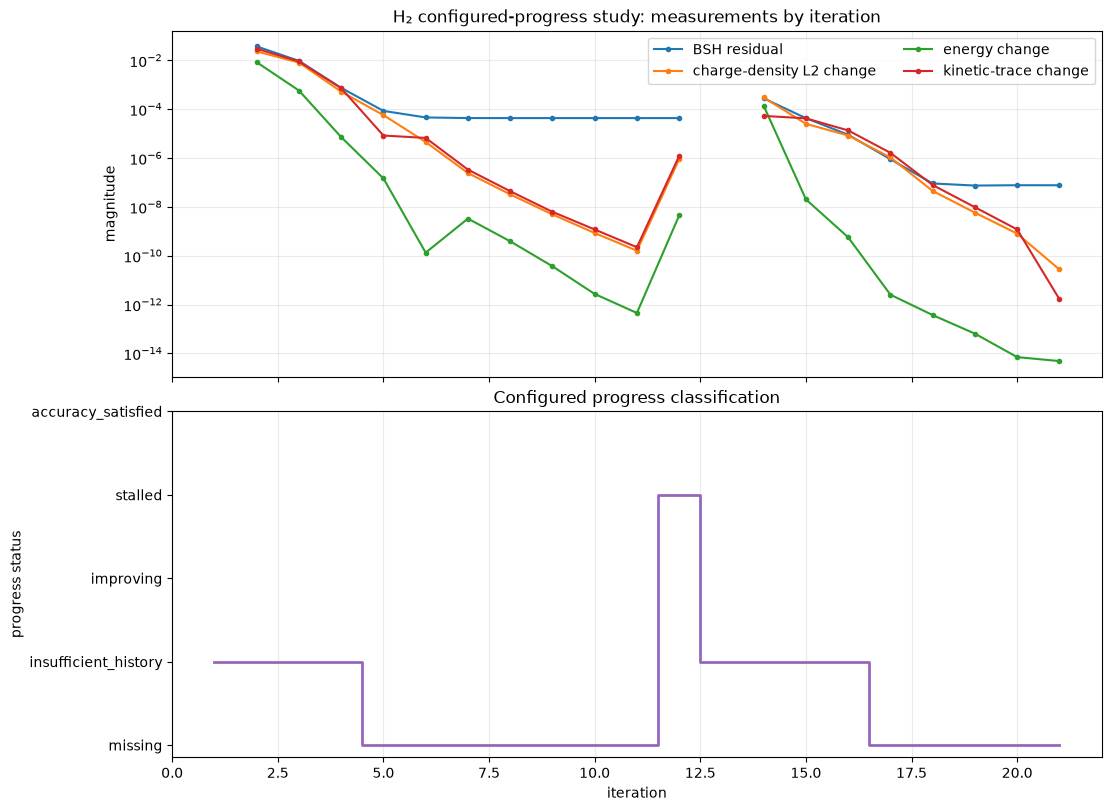

In [2]:
hist = scf['result']['convergence_report']['iteration_history']
it = np.arange(1, len(hist)+1)
def metric(name, key='value'):
    out=[]
    for row in hist:
        x=row.get('measurements',{}).get(name,{})
        out.append(np.nan if x.get(key) is None else x.get(key))
    return np.asarray(out, dtype=float)

fig, ax = plt.subplots(2, 1, figsize=(11, 8), sharex=True, constrained_layout=True)
series = [('bsh_residual','BSH residual'), ('charge_density_change','charge-density L2 change'), ('energy_change','energy change'), ('delta_kinetic_energy','kinetic-trace change')]
for name, label in series:
    y=metric(name)
    ax[0].plot(it, y, marker='o', ms=3, label=label)
ax[0].set_yscale('log'); ax[0].set_ylabel('magnitude'); ax[0].set_title('H₂ configured-progress study: measurements by iteration')
ax[0].grid(True, which='both', alpha=.25); ax[0].legend(ncol=2)
status=[r.get('configured_progress',{}).get('status','missing') for r in hist]
code={'insufficient_history':0, 'improving':1, 'stalled':2, 'accuracy_satisfied':3, 'missing':-1}
y=[code.get(s,-1) for s in status]
ax[1].step(it, y, where='mid', lw=2, color='tab:purple'); ax[1].set_yticks(list(code.values()), list(code.keys()))
ax[1].set_xlabel('iteration'); ax[1].set_ylabel('progress status'); ax[1].set_title('Configured progress classification')
ax[1].grid(True, axis='x', alpha=.25)
plt.show()

## 2. Forced trajectories: extra iterations are scientifically visible

These bars compare ordinary stopping with forced iteration counts. The property shifts are useful for deciding whether a protocol is merely stopping early or whether more iterations materially change the requested observable. They are evidence for this molecule and setup only.

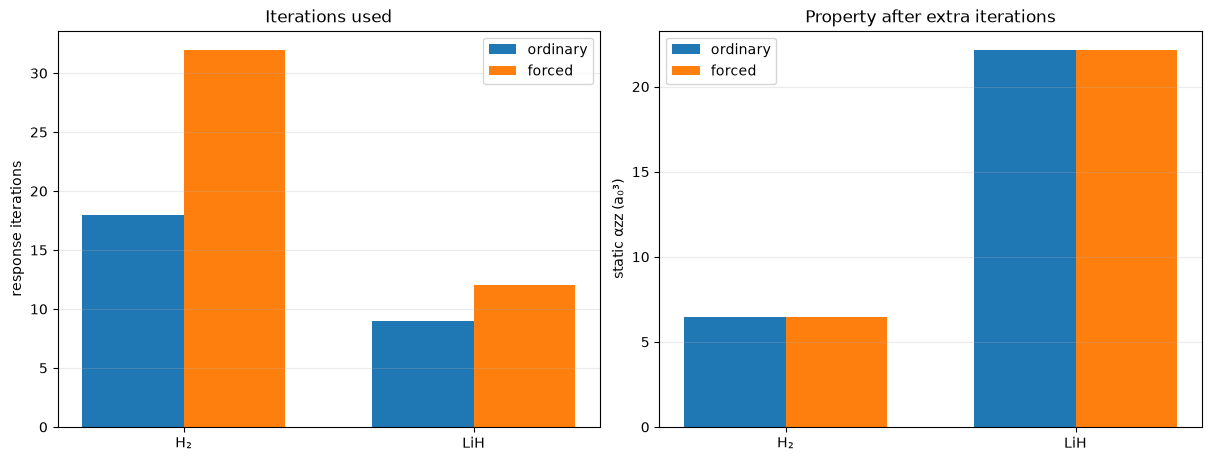

H₂: Δαzz = -2.1416257e-05 a0^3
LiH: Δαzz = +0.019851156 a0^3


In [3]:
def response_properties(d):
    # H₂ evidence uses `properties`; LiH evidence uses `response_properties`.
    return d.get('properties', d.get('response_properties'))
def alpha0(d):
    return response_properties(d)['polarizability']['values'][0]['components']['zz']
def alpha0_base(d):
    if 'baseline_response_properties' in d:
        return d['baseline_response_properties']['polarizability']['values'][0]['components']['zz']
    # H₂ records forced-minus-ordinary deltas instead of a full baseline object.
    return alpha0(d) - d['alpha_deltas'][0]['delta_zz']
names=['H₂','LiH']; regular=[forced_h2['regular_iterations'][1], forced_lih['baseline_iterations'][1]]; forced=[forced_h2['response_iterations'], forced_lih['actual_iterations'][1]]
alphas=[alpha0(forced_h2),alpha0(forced_lih)]; bases=[alpha0_base(forced_h2),alpha0_base(forced_lih)]
x=np.arange(2); w=.35
fig, ax=plt.subplots(1,2,figsize=(12,4.5),constrained_layout=True)
ax[0].bar(x-w/2,regular,w,label='ordinary'); ax[0].bar(x+w/2,forced,w,label='forced')
ax[0].set_xticks(x,names); ax[0].set_ylabel('response iterations'); ax[0].set_title('Iterations used'); ax[0].legend()
ax[1].bar(x-w/2,bases,w,label='ordinary'); ax[1].bar(x+w/2,alphas,w,label='forced')
ax[1].set_xticks(x,names); ax[1].set_ylabel('static αzz (a₀³)'); ax[1].set_title('Property after extra iterations'); ax[1].legend()
for a in ax: a.grid(axis='y',alpha=.25)
plt.show()
for n,b,a in zip(names,bases,alphas): print(f'{n}: Δαzz = {a-b:+.8g} a0^3')

## 3. LiH forced ground-state measurements

The LiH run is longer and exposes the relationship between the trace quantity and the conventional physical kinetic energy. The trace is unweighted; the physical value is separately occupation-weighted. Plotting both makes accidental substitution visible.

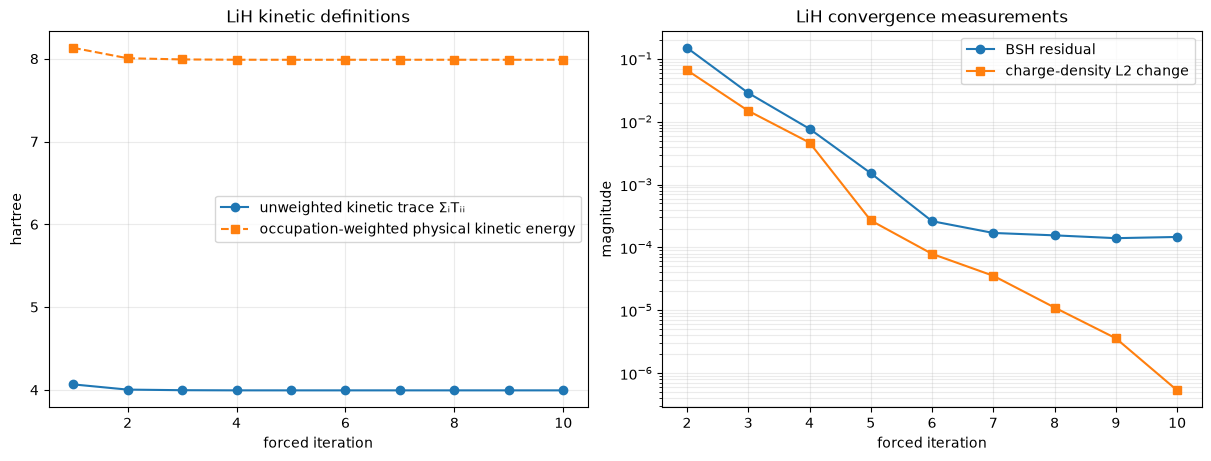

In [4]:
lh=forced_lih['ground_history']; k=np.arange(1,len(lh)+1)
trace=np.array([r['kinetic_trace']['value'] for r in lh])
physical=np.array([r['occupation_weighted_physical_kinetic_energy']['value'] for r in lh])
bsh=np.array([r['measurements']['bsh_residual']['value'] if r['measurements']['bsh_residual']['value'] is not None else np.nan for r in lh])
charge=np.array([r['measurements']['charge_density_change']['value'] if r['measurements']['charge_density_change']['value'] is not None else np.nan for r in lh])
fig,ax=plt.subplots(1,2,figsize=(12,4.5),constrained_layout=True)
ax[0].plot(k,trace,'o-',label='unweighted kinetic trace ΣᵢTᵢᵢ'); ax[0].plot(k,physical,'s--',label='occupation-weighted physical kinetic energy')
ax[0].set_xlabel('forced iteration'); ax[0].set_ylabel('hartree'); ax[0].set_title('LiH kinetic definitions'); ax[0].legend(); ax[0].grid(alpha=.25)
ax[1].plot(k,bsh,'o-',label='BSH residual'); ax[1].plot(k,charge,'s-',label='charge-density L2 change')
ax[1].set_yscale('log'); ax[1].set_xlabel('forced iteration'); ax[1].set_ylabel('magnitude'); ax[1].set_title('LiH convergence measurements'); ax[1].legend(); ax[1].grid(which='both',alpha=.25)
plt.show()

## 4. What the trajectories suggest

The traces support a staged design: keep raw measurements and their phase/identity, evaluate user-requested accuracy separately, and use a progress window to decide whether to advance a supplied protocol rung. Do not turn the forced runs into default tolerances. The observable changes in the second plot are large enough to justify reporting an unmet final target, but they do not by themselves identify a universal threshold.

The next design review should settle whether explicit user criteria are an additional requirement (Astra's interpretation) or replace the legacy solver gate (Fable's interpretation). The evidence favors keeping these concepts separate until that policy is explicit.

## 5. Protocol rungs and ground-to-response coupling

This view makes the protocol explicit. Each shaded region is a supplied rung, and the dashed boundary marks the switch. Response channels are plotted by frequency and rung so we can ask whether the response work is dominated by the quality of the ground-state reference or by its own response residual.

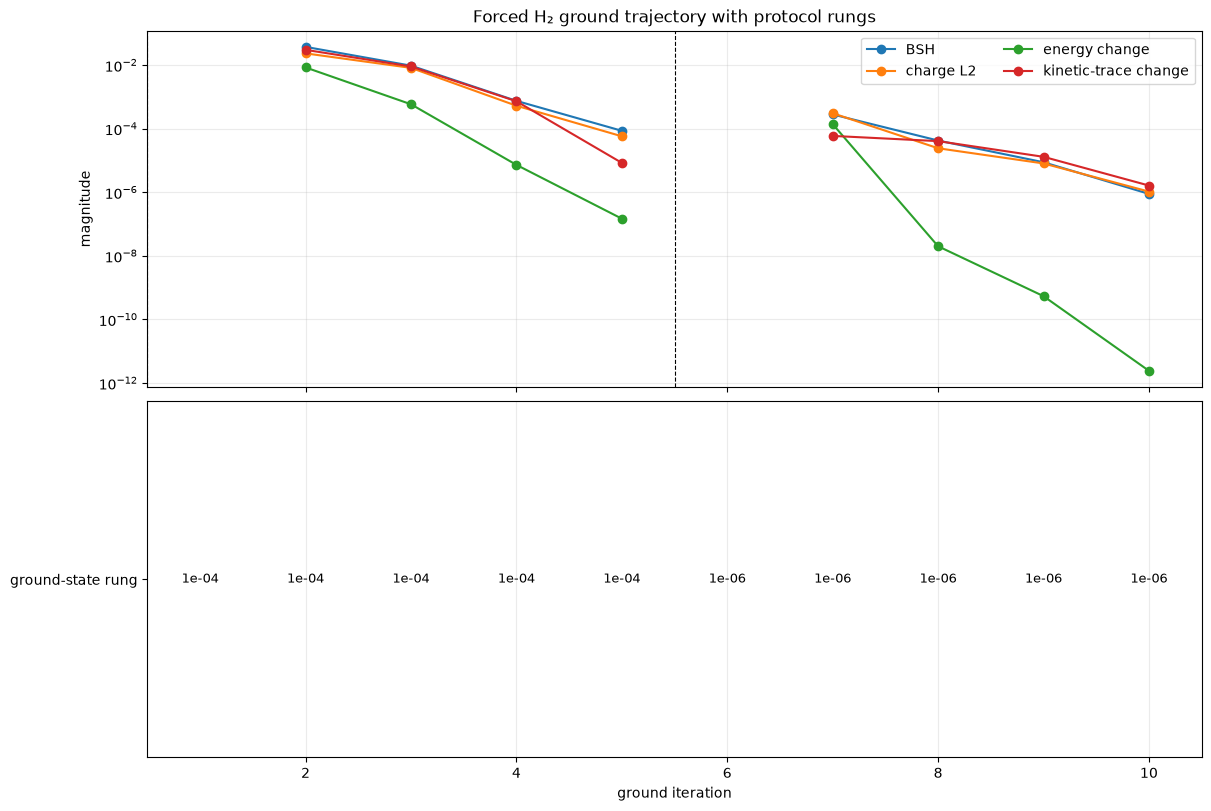

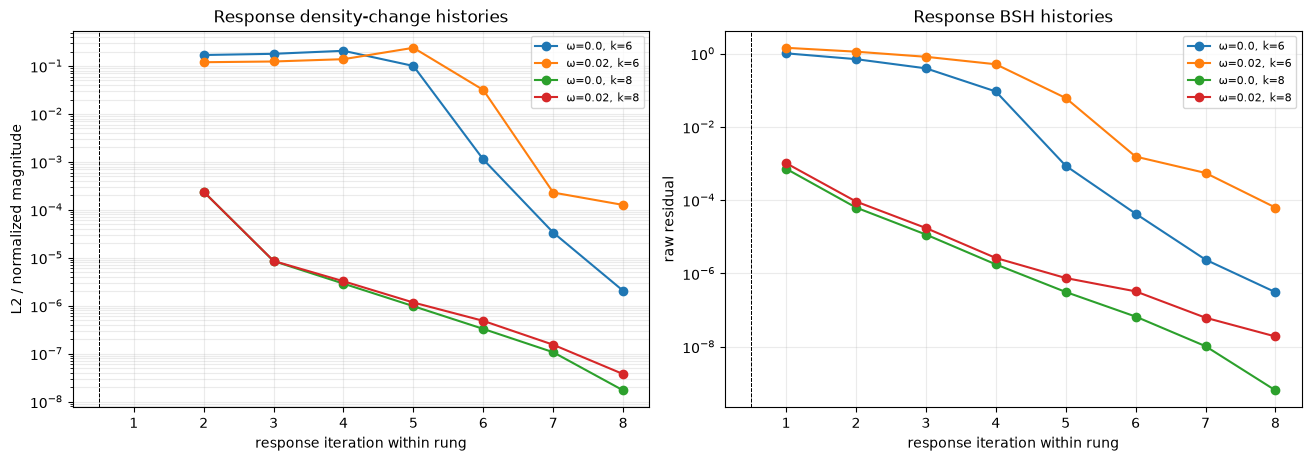

In [5]:
def rung_label(threshold):
    return f'{threshold:.0e}'

def rung_segments(history, sample_key=('kinetic_trace','sample')):
    labels=[]
    for row in history:
        x=row
        for key in sample_key: x=x.get(key,{})
        labels.append(rung_label(x.get('threshold', np.nan)))
    return labels

gh=forced_h2['ground_history']; gx=np.arange(1,len(gh)+1); gl=rung_segments(gh)
fig,ax=plt.subplots(2,1,figsize=(12,8),sharex=True,constrained_layout=True)
for name,label in [('bsh_residual','BSH'),('charge_density_change','charge L2'),('energy_change','energy change'),('delta_kinetic_energy','kinetic-trace change')]:
    y=np.array([row['measurements'][name]['value'] if row['measurements'][name]['value'] is not None else np.nan for row in gh])
    ax[0].plot(gx,y,'o-',label=label)
ax[0].set_yscale('log'); ax[0].set_ylabel('magnitude'); ax[0].set_title('Forced H₂ ground trajectory with protocol rungs'); ax[0].grid(which='both',alpha=.25); ax[0].legend(ncol=2)
for i,lab in enumerate(gl):
    if i==0 or lab!=gl[i-1]: ax[0].axvline(i+.5,color='k',ls='--',lw=.8)
for i,lab in enumerate(gl): ax[1].text(i+1,0.5,lab,ha='center',va='center',fontsize=9)
ax[1].set_yticks([0.5],['ground-state rung']); ax[1].set_xlabel('ground iteration'); ax[1].set_xlim(.5,len(gh)+.5); ax[1].set_ylim(0,1); ax[1].grid(axis='x',alpha=.25)
plt.show()

channels=forced_h2['response_channels']
fig,ax=plt.subplots(1,2,figsize=(13,4.5),constrained_layout=True)
for c in channels:
    label=f"ω={c['frequency']}, k={c['protocol']['k']}"
    x=np.arange(1,len(c['density_history'])+1)
    y=np.array([h['value'] if h['value'] is not None else np.nan for h in c['density_history']])
    b=np.array([h['value'] if h['value'] is not None else np.nan for h in c['function_bsh_history']])
    ax[0].plot(x,y,'o-',label=label)
    ax[1].plot(x,b,'o-',label=label)
    if c['protocol']['k']==8: ax[0].axvline(0.5,color='k',ls='--',lw=.7); ax[1].axvline(0.5,color='k',ls='--',lw=.7)
ax[0].set_yscale('log'); ax[0].set_title('Response density-change histories'); ax[0].set_xlabel('response iteration within rung'); ax[0].set_ylabel('L2 / normalized magnitude'); ax[0].grid(which='both',alpha=.25); ax[0].legend(fontsize=8)
ax[1].set_yscale('log'); ax[1].set_title('Response BSH histories'); ax[1].set_xlabel('response iteration within rung'); ax[1].set_ylabel('raw residual'); ax[1].grid(which='both',alpha=.25); ax[1].legend(fontsize=8)
plt.show()

## 6. Exhausted-rung endpoint table

The table below is the comparison we need before changing stopping policy: what did the ground-state metrics look like at the end of each rung, and how many response iterations did that rung require?

In [6]:
def endpoint_rows(history):
    groups={}
    for row in history:
        t=row['kinetic_trace']['sample']['threshold']; groups.setdefault(t,[]).append(row)
    rows=[]
    for t,items in groups.items():
        last=items[-1]; m=last['measurements']
        rows.append({'protocol':t,'ground_iterations':len(items),'charge_L2':m['charge_density_change']['value'],'BSH':m['bsh_residual']['value'],'energy_change':m['energy_change']['value'],'kinetic_trace_change':m['delta_kinetic_energy']['value']})
    return rows
for row in endpoint_rows(gh): print(row)
print('\nResponse work by rung/frequency:')
for c in channels: print({'frequency':c['frequency'],'k':c['protocol']['k'],'response_iterations':c['iterations_at_save'],'last_density':c['density_history'][-1]['value'],'last_bsh':c['function_bsh_history'][-1]['value']})

{'protocol': 0.0001, 'ground_iterations': 5, 'charge_L2': 5.769308967141696e-05, 'BSH': 8.592420912092224e-05, 'energy_change': 1.4767987854824582e-07, 'kinetic_trace_change': 8.415919327209309e-06}
{'protocol': 1e-06, 'ground_iterations': 5, 'charge_L2': 1.0502645233115695e-06, 'BSH': 8.888771159200631e-07, 'energy_change': 2.4140689447449404e-12, 'kinetic_trace_change': 1.6277491160510138e-06}

Response work by rung/frequency:
{'frequency': 0.0, 'k': 6, 'response_iterations': 8, 'last_density': 2.0462105263987474e-06, 'last_bsh': 3.0496222807000037e-07}
{'frequency': 0.02, 'k': 6, 'response_iterations': 8, 'last_density': 0.00012645031608665296, 'last_bsh': 6.234019021726898e-05}
{'frequency': 0.0, 'k': 8, 'response_iterations': 8, 'last_density': 1.7110944277038618e-08, 'last_bsh': 6.370835111813495e-10}
{'frequency': 0.02, 'k': 8, 'response_iterations': 8, 'last_density': 3.745620371806663e-08, 'last_bsh': 1.885049538567572e-08}


## 7. Optional field-level density comparison with pymra

The scalar JSON evidence cannot show where a density difference lives. This section reads the structured `.mad.h5` exports created with `dump_mra_trees --coeffs`. The native application HDF5 files are also retained in the session folder, but they contain a `madness_archive` byte stream and are not directly accepted by `pymra.read_function`.

The comparison uses matched H₂ ground-state endpoints and constructs the closed-shell density proxy `rho = 2 psi_alpha^2` on a common midpoint grid. It is a field-level ground-state comparison; no response-state density is inferred from it.


pymra field comparison: H2 coarse vs fine ground-state endpoint
common grid: 64 ^3 points; cell: (-20.0, 20.0) bohr
coarse density L2: 0.40234687333805885
fine density L2: 0.4023142057688177
density difference L2: 4.790198304761096e-05
density difference max abs: 2.8245134813892347e-05
density difference RMS: 1.8934921358653068e-07
inner r<3 L2: 4.786505291498861e-05
outer r>=3 L2: 1.880608768177862e-06


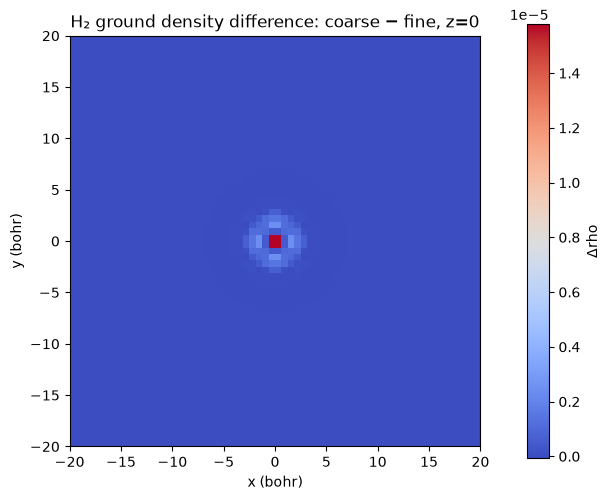

In [7]:
try:
    import h5py
    from pymra import read_function, eval_points
    HAVE_HDF5_ANALYSIS = True
except ImportError as exc:
    HAVE_HDF5_ANALYSIS = False
    print("pymra/h5py unavailable:", exc)

HDF5_ROOT = VAULT / "hdf5-analysis"
coarse_path = HDF5_ROOT / "h2-coarse" / "mo_0.mad.h5"
fine_path = HDF5_ROOT / "h2-fine" / "mo_0.mad.h5"
if not HAVE_HDF5_ANALYSIS or not (coarse_path.exists() and fine_path.exists()):
    print("Field-level comparison unavailable; missing dependencies or structured exports.")
else:
    coarse_tree = read_function(str(coarse_path))
    fine_tree = read_function(str(fine_path))
    ngrid = 64
    lo, hi = -20.0, 20.0
    axis = np.linspace(lo + (hi-lo)/(2*ngrid), hi - (hi-lo)/(2*ngrid), ngrid)
    X, Y, Z = np.meshgrid(axis, axis, axis, indexing="ij")
    points = np.column_stack((X.ravel(), Y.ravel(), Z.ravel()))
    coarse_orb = np.asarray(eval_points(coarse_tree, points), dtype=float)
    fine_orb = np.asarray(eval_points(fine_tree, points), dtype=float)
    coarse_rho, fine_rho = 2*coarse_orb**2, 2*fine_orb**2
    delta_rho = coarse_rho - fine_rho
    dv = ((hi-lo)/ngrid)**3
    radius = np.sqrt(np.sum(points*points, axis=1))
    inner = radius < 3.0
    print("pymra field comparison: H2 coarse vs fine ground-state endpoint")
    print("common grid:", ngrid, "^3 points; cell:", (lo, hi), "bohr")
    print("coarse density L2:", np.sqrt(np.sum(coarse_rho**2)*dv))
    print("fine density L2:", np.sqrt(np.sum(fine_rho**2)*dv))
    print("density difference L2:", np.sqrt(np.sum(delta_rho**2)*dv))
    print("density difference max abs:", np.max(np.abs(delta_rho)))
    print("density difference RMS:", np.sqrt(np.mean(delta_rho**2)))
    print("inner r<3 L2:", np.sqrt(np.sum(delta_rho[inner]**2)*dv))
    print("outer r>=3 L2:", np.sqrt(np.sum(delta_rho[~inner]**2)*dv))
    # A central z=0 slice makes spatial concentration visible without implying an exact MRA norm.
    mid = ngrid // 2
    delta_grid = delta_rho.reshape((ngrid, ngrid, ngrid))
    fig, ax = plt.subplots(figsize=(6, 5), constrained_layout=True)
    im = ax.imshow(delta_grid[:, :, mid], origin="lower", extent=(lo, hi, lo, hi), cmap="coolwarm")
    ax.set_xlabel("x (bohr)"); ax.set_ylabel("y (bohr)")
    ax.set_title("H₂ ground density difference: coarse − fine, z=0")
    fig.colorbar(im, ax=ax, label="Δrho")
    plt.show()


The HDF5-enabled H₂ response run used the `1e-4`, `k=6` protocol and completed the static finite-difference response in 12 iterations (`alpha_zz = 6.43530186`) and the excited-state bundle in 5 iterations (lowest omega about `0.46585701` a.u.). Its native response archives are listed in the session artifact directory.

The coarse/fine density comparison is concentrated in the molecular core: the inner `r<3` contribution is about `4.79e-5` versus `1.88e-6` outside. This indicates that endpoint field differences are spatially localized, but it does not yet establish whether response convergence is reference-limited.


## 8. Endpoint-indexed run matrix

This view indexes response runs by the ground-state endpoint they consumed. A partial or time-bounded case stays visible and is never counted as a completed convergence reference.


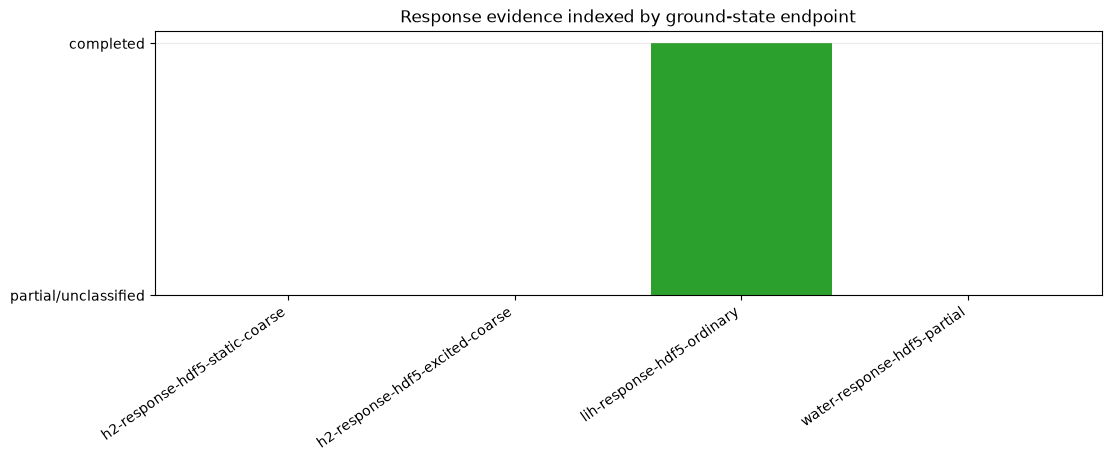

h2-response-hdf5-static-coarse endpoint= h2-gs-coarse-hdf5 status= recorded protocol= {'threshold': 0.0001, 'k': 6, 'frequency': 0.0, 'state': 'static_dipole_z'}
h2-response-hdf5-excited-coarse endpoint= h2-gs-coarse-hdf5 status= recorded protocol= {'threshold': 0.0001, 'k': 6, 'state': 'es_full'}
lih-response-hdf5-ordinary endpoint= lih-gs-1e-04 status= completed protocol= {'thresholds': [0.0001]}
water-response-hdf5-partial endpoint= water-gs-1e-04-partial status= interrupted-time-budget protocol= {'thresholds': [0.0001, 1e-06]}


In [8]:
manifest = json.loads((ROOT / "analysis" / "madqc_convergence_manifest.json").read_text())
rows = [r for r in manifest["runs"] if r["workflow"] == "response"]
labels = [r["run_id"] for r in rows]
status = [r.get("status", "recorded") for r in rows]
complete = [1 if s == "completed" else 0 for s in status]
fig, ax = plt.subplots(figsize=(11, 4.5), constrained_layout=True)
colors = ["tab:green" if x else "tab:orange" for x in complete]
ax.bar(np.arange(len(rows)), complete, color=colors)
ax.set_xticks(np.arange(len(rows)), labels, rotation=35, ha="right")
ax.set_yticks([0, 1], ["partial/unclassified", "completed"])
ax.set_title("Response evidence indexed by ground-state endpoint")
ax.grid(axis="y", alpha=.25)
plt.show()
for row in rows:
    print(row["run_id"], "endpoint=", row["ground_state_endpoint"], "status=", row.get("status", "recorded"), "protocol=", row["protocol"])
